In [2]:
import sys
sys.path.insert(0,"../src")

import numpy as np
import matplotlib.pyplot as plt

from option_hedging.simulation import simulate_gbm_paths
from option_hedging.pricing import V_t_func
from option_hedging.hedging import simulate_delta_hedging
from option_hedging.optimization import phi, generate_qopt

### Parameters

In [3]:
S0 = 107         # initial stock price
mu = 0.14        # drift
T = 1.40         # maturity
r = 0.04         # risk-free rate
K_c = 90         # call strike
K_p = 107        # put strike
b0 = 132         # initial bank balance
theta = 0.01     # transaction cost rate
lbda = 0.01      # risk aversion
n_steps = 32     # rebalancing steps
n_paths = 100000 # simulated paths 

### Simulate stock paths

In [4]:
np.random.seed(42)
S, times = simulate_gbm_paths(S0, mu, T, n_steps, n_paths)
print(S.shape)
print(S[:5, 0]) # should all be S0

(100000, 33)
[107. 107. 107. 107. 107.]


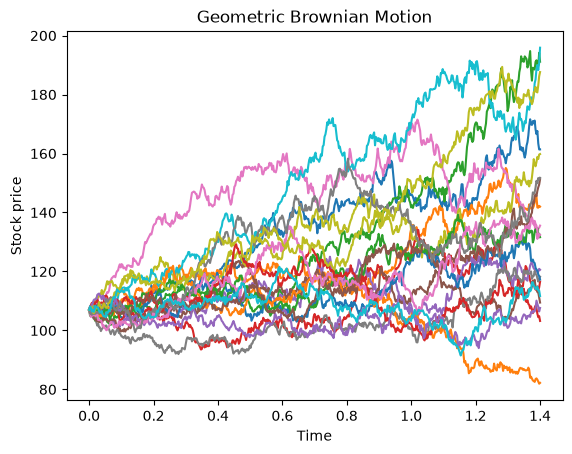

In [9]:
n_steps_large = 500
np.random.seed(1)
S_many, times_many = simulate_gbm_paths(S0, mu, T, n_steps_large, 20)

fig, ax = plt.subplots()
for i in range(20):
    ax.plot(times_many, S_many[i])
ax.set_xlabel('Time')
ax.set_ylabel('Stock price')
ax.set_title('Geometric Brownian Motion')
plt.show()

#### Price the option matrix

In [12]:
V = V_t_func(S0, S, times, K_c, K_p, T, r, None, n_paths)
print(V.shape)
print(V[:5, -1])   # last column -- should be real payoffs, not zero
print(S[:5, -1])   # compare against the stock price at maturity

(100000, 33)
[17.         17.         38.48677576 51.58477404 30.1503633 ]
[105.07807474  96.88211403 128.48677576 141.58477404 120.1503633 ]


#### Wealth and φ for the four pure strategies

| Label | q1 | q2 | q3 | What it does |
|---|---|---|---|---|
| Do nothing | 0 | 0 | 0 | Cash only, no trading |
| Buy & hold stock | 1 | 0 | 0 | Constant stock holding, no hedging, no options |
| Delta-hedge | 0 | 1 | 0 | Pure delta-hedging, no option held |
| Buy & hold option | 0 | 0 | 1 | Buy the option once, hold to maturity |

In [13]:
strategies = {
    'Do nothing': (0,0,0),
    'Buy & hold stock': (1,0,0),
    'Delta-hedge': (0,1,0),
    'Buy & hold option': (0,0,1),
}

wealth = {}
for name, q in strategies.items():
    wealth[name] = simulate_delta_hedging(S0, K_c, K_p, T, r, mu, None, n_steps, n_paths, theta, q, b0, S, times)
    print(f"{name}: phi = {phi(wealth[name], lbda, b0):.6f}   mean = {wealth[name].mean():.2f}")

Do nothing: phi = 1.057598   mean = 139.60
Buy & hold stock: phi = 1.149972   mean = 155.37
Delta-hedge: phi = 1.102749   mean = 148.35
Buy & hold option: phi = 1.123615   mean = 150.99


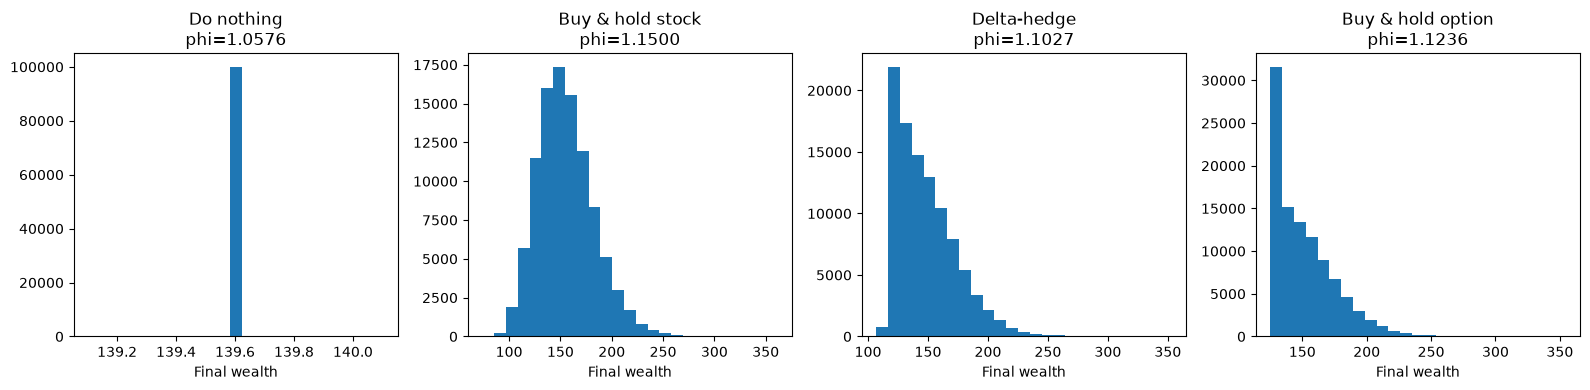

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, w) in zip(axes, wealth.items()):
    ax.hist(w, bins=25)
    ax.set_title(f"{name}\nphi={phi(w, lbda, b0):.4f}")
    ax.set_xlabel('Final wealth')
plt.tight_layout()
plt.show()

#### Optimal strategy


phi is a scaled measure of expected utility; it comes from
the trader's CARA utility u(b) = -exp(-lambda*b), rescaled so that
phi = -1/(b0*lambda) * log(E[-u(b_T)]). As a sanity check, phi for the
"do nothing" strategy equals exp(r*T) exactly, since that strategy's wealth
has zero variance.

Here our objective is to find the (q1, q2, q3) that maximises phi, subject to the t=0 budget constraint.


In [15]:
qOpt_a, res_a = generate_qopt(S0, K_c, K_p, T, r, mu, theta, lbda, b0, n_steps, n_paths, x0=[1,1,1])
qOpt_b, res_b = generate_qopt(S0, K_c, K_p, T, r, mu, theta, lbda, b0, n_steps, n_paths, x0=[5,-5,5])

print("Start [1,1,1]: ", qOpt_a, " phi =", -res_a.fun)
print("Start [5,-5,5]:", qOpt_b, " phi =", -res_b.fun)

Objective evaluations: 82eval [00:30,  2.73eval/s]
Objective evaluations: 121eval [00:46,  2.63eval/s]

Start [1,1,1]:  [8.04691928e-01 7.77776362e-06 1.51907769e+00]  phi = 1.179180570055582
Start [5,-5,5]: [ 8.03924177e-01 -9.45377390e-06  1.52190957e+00]  phi = 1.1788125048114122


In [17]:
qOpt_c, res_c = generate_qopt(S0, K_c, K_p, T, r, mu, theta, lbda, b0, n_steps, n_paths, x0=[-3,10,8])

print("Start [-3,10,8]: ", qOpt_c, " phi =", -res_c.fun)

Objective evaluations: 102eval [00:37,  2.74eval/s]

Start [-3,10,8]:  [7.10548594e-01 7.83668592e-06 1.86224820e+00]  phi = 1.1793706833993554


In [18]:
qOpt = qOpt_a   # from the [1,1,1] start; the three starts agree closely (see above)
print("Optimal q:", qOpt)
print("Optimal phi:", -res_a.fun)

Optimal q: [8.04691928e-01 7.77776362e-06 1.51907769e+00]
Optimal phi: 1.179180570055582


#### Sensitivity to step size and risk aversion (theta = 0)

With transaction costs switched off, how does the optimal strategy depend on
the rebalancing frequency and the risk-aversion parameter lambda?


Objective evaluations: 64eval [00:21,  2.95eval/s]
Objective evaluations: 52eval [00:23,  2.22eval/s]
Objective evaluations: 52eval [00:29,  1.74eval/s]
Objective evaluations: 64eval [01:28,  1.38s/eval]


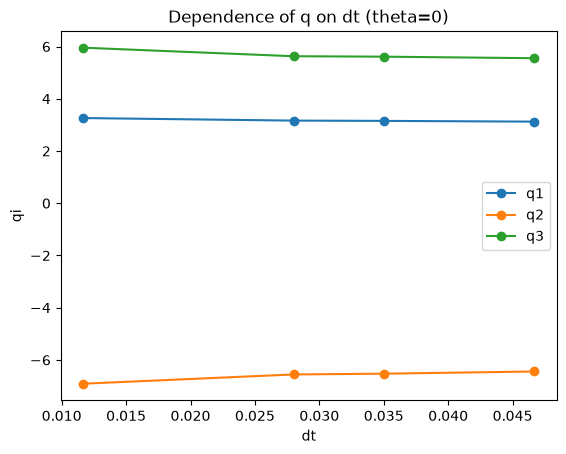

In [19]:
dt_steps = [30, 40, 50, 120]
q_dt_results = []
for n in dt_steps:
    q_opt, _ = generate_qopt(S0, K_c, K_p, T, r, mu, theta=0, lbda=lbda, b0=b0, n_steps=n, n_paths=n_paths)
    q_dt_results.append(q_opt)
q_dt_results = np.array(q_dt_results)

dts = [T/n for n in dt_steps]
fig, ax = plt.subplots()
for i, label in enumerate(['q1', 'q2', 'q3']):
    ax.plot(dts, q_dt_results[:, i], marker='o', label=label)
ax.set_xlabel('dt')
ax.set_ylabel('qi')
ax.set_title('Dependence of q on dt (theta=0)')
ax.legend()
plt.show()

Objective evaluations: 76eval [00:27,  2.73eval/s]
Objective evaluations: 72eval [00:26,  2.70eval/s]
Objective evaluations: 44eval [00:16,  2.69eval/s]
Objective evaluations: 44eval [00:16,  2.69eval/s]


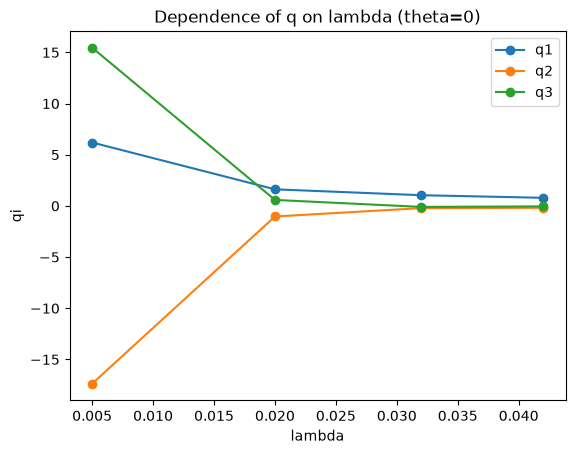

In [20]:
lambda_values = [0.005, 0.02, 0.032, 0.042]
q_lambda_results = []
for lam in lambda_values:
    q_opt, _ = generate_qopt(S0, K_c, K_p, T, r, mu, theta=0, lbda=lam, b0=b0, n_steps=n_steps, n_paths=n_paths)
    q_lambda_results.append(q_opt)
q_lambda_results = np.array(q_lambda_results)

fig, ax = plt.subplots()
for i, label in enumerate(['q1', 'q2', 'q3']):
    ax.plot(lambda_values, q_lambda_results[:, i], marker='o', label=label)
ax.set_xlabel('lambda')
ax.set_ylabel('qi')
ax.set_title('Dependence of q on lambda (theta=0)')
ax.legend()
plt.show()